**ANOMALY DETECTION OC-SVM**

In [1]:
import digitalhub as dh
import zipfile
import json
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

PROJECT_NAME = "floods"
project = dh.get_project(PROJECT_NAME)
print(f"Project: {project.name}")

Project: floods


**SETUP PARAMETERS**

In [2]:
job_name = "net_v3_40per_w"
dataset_standard = "Standard"
dataset_anomalies = "Floods_Anomalies_v3_crop_norm"
moco_version = "net_v3"

parameters = {
    "job_name": job_name,                          
    "dataset_standard": dataset_standard,
    "dataset_anomalies": dataset_anomalies,         
    "moco_version": moco_version, 
    "old_vectors": "net_v3_0per", 
    "ocsvm_nu": 0.05,                       
    "ocsvm_gamma": "scale", 
    "min_flood_area": 40.0,                 
    
    "simple_proj": False,                          
    "attn": False,                                  
    "hidden_channels_dim": 64,
    "pool_grid": 4,
    "moco_dim": 128,
    "moco_k": 4096,
    "moco_m": 0.999,
    "moco_t": 0.07,
    "patch_size": 256,
    "n_images1": 4, "n_channels1": 2,       # sar
    "n_images2": 4, "n_channels2": 10,      # ottico       
    "standardize": True,                    
    "batch_size": 16,
    "workers": 0,
}

volumes = [
    {
        "volume_type": "ephemeral",
        "name": "volume-spazio-dati",
        "mount_path": "/data",
        "spec": {"size": "200Gi"}
    }
]

**BUILD ENVIRONMENT**

In [3]:
ad_ocsvm_func = project.new_function(
    name=f'ad_ocsvm_{job_name}',
    kind="python",
    python_version="PYTHON3_10",
    code_src="../src/",
    handler="anomaly:ad_ocsvm",
    base_image="pytorch/pytorch:2.1.2-cuda11.8-cudnn8-runtime",
    requirements=["pandas==2.3.3", "numpy==1.26.4", "rasterio==1.4.4", "tqdm==4.70.0", "tifffile==2024.8.30", "torch==2.1.2", "matplotlib==3.10.9", "digitalhub==0.15.11", "digitalhub-runtime-python==0.15.2", "zarr==2.18.0", "numcodecs==0.13.1", "xarray==2025.6.1", "scikit-learn==1.5.2"]
)

build = ad_ocsvm_func.run("build", wait=True)
print(f"BUILD: {build.status.state}")

2026-10-13 18:41:20,441 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 20d8826f20f647f3a8bc92e3f8f44fe0 to finish...
2026-10-13 18:41:25,447 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 20d8826f20f647f3a8bc92e3f8f44fe0 to finish...
2026-10-13 18:41:30,456 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 20d8826f20f647f3a8bc92e3f8f44fe0 to finish...
2026-10-13 18:41:35,464 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 20d8826f20f647f3a8bc92e3f8f44fe0 to finish...
2026-10-13 18:41:40,472 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 20d8826f20f647f3a8bc92e3f8f44fe0 to finish...
2026-10-13 18:41:45,480 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 20d8826f20f647f3a8bc92e3f8f44fe0 to finish...
2026-10-13 18:41:50,488 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 20d8826f20f647f3a8bc92e3f8f44fe0 to finish...
2026-10-13 18

BUILD: COMPLETED


**TRAINING**

In [4]:
run_ad = ad_ocsvm_func.run(
    action="job",
    parameters=parameters,
    volumes=volumes,
    profile="1xv100-shared",
    local_execution=False,
    wait=True
)

print(f"Run anomaly detection OC-SVM avviato: {run_ad.id}")

2026-10-13 18:42:15,586 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...


2026-10-13 18:42:20,592 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...
2026-10-13 18:42:25,601 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...
2026-10-13 18:42:30,610 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...
2026-10-13 18:42:35,618 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...
2026-10-13 18:42:40,627 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...
2026-10-13 18:42:45,637 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...
2026-10-13 18:42:50,646 - dhcore.digitalhub.entities.run._base.entity - INFO - Waiting for run 8306ce5354584a78a531d0a98562e06a to finish...
2026-10-13 18

Run anomaly detection OC-SVM avviato: 8306ce5354584a78a531d0a98562e06a


In [5]:
RESULTS_DIR = "/tmp/anomaly_results_ocsvm"

zip_path = project.get_artifact(f"anomaly_results_ocsvm_{job_name}").download("/tmp/anomaly_results_ocsvm.zip", overwrite=True)
with zipfile.ZipFile(zip_path) as z:
    z.extractall(RESULTS_DIR)
with open(f"{RESULTS_DIR}/anomaly_results.json") as f:
    results = json.load(f)

df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")                    
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

print(f"n_fit: {results['n_fit']} | n_normali: {results['n_normali']} | n_anomale: {results['n_anomale']}", "\n")
print(f"nu: {results['ocsvm']['nu']} | gamma: {results['ocsvm']['gamma']} | dim: {results['ocsvm']['dim']} | frac_outside_fit: {results['ocsvm']['frac_outside_fit']}") 
print(f"min_flood_area={results['min_flood_area']:.3f} ")
print(f"score normali: {score_normal.mean():.4f} ± {score_normal.std():.4f}")
print(f"score anomale: {score_anom.mean():.4f} ± {score_anom.std():.4f}", "\n")
print(f"AUROC: {results['auroc']:.3f}")

df_rules = pd.DataFrame(results['rules']).T
df_rules

n_fit: 2572 | n_normali: 642 | n_anomale: 642 

nu: 0.05 | gamma: scale | dim: 256 | frac_outside_fit: 0.049766718506998445
min_flood_area=40.000 
score normali: 1.7725 ± 1.7010
score anomale: -0.8871 ± 1.6670 

AUROC: 0.869


,soglia,TP,FP,FN,TN,FA_rate,MA_rate,REC,PREC,F1
ocsvm score < 0,0.0,448.0,88.0,194.0,554.0,0.137072,0.302181,0.697819,0.835821,0.760611


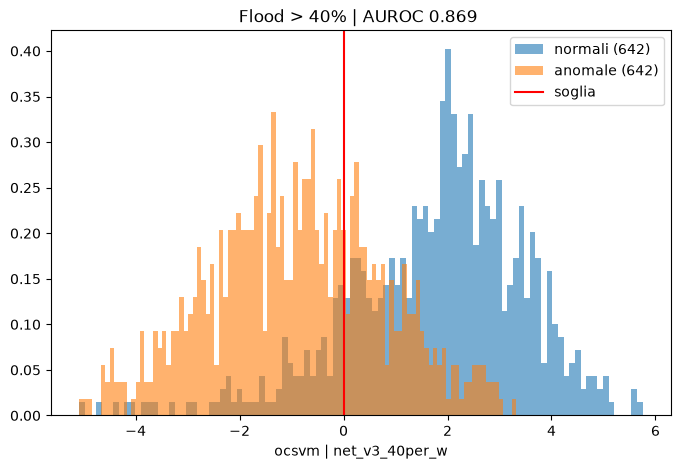

In [6]:
df = pd.read_csv(f"{RESULTS_DIR}/scores.csv")
score_normal = df[df.label == 0]['score']
score_anom = df[df.label == 1]['score']

plt.figure(figsize=(8, 5))
plt.hist(score_normal, bins=100, alpha=0.6, density=True, label=f"normali ({len(score_normal)})")
plt.hist(score_anom, bins=100, alpha=0.6, density=True, label=f"anomale ({len(score_anom)})")
plt.axvline(x=0, color='r', label='soglia')
plt.xlabel(f"ocsvm | {job_name}")
plt.legend()
plt.title(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f} ")
plt.show()

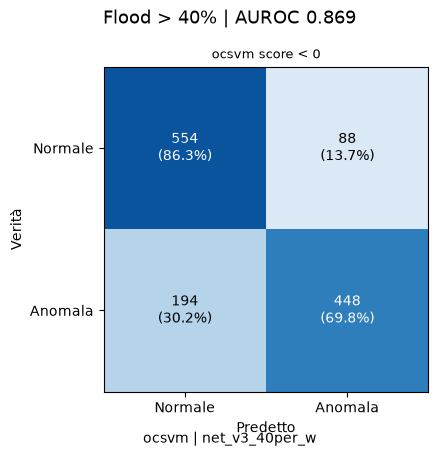

In [7]:
rules = results['rules']
fig, axes = plt.subplots(1, len(rules), figsize=(5 * len(rules), 4.5), squeeze=False)

for ax, (nome, r) in zip(axes[0], rules.items()):
    mat = np.array([[r["TN"], r["FP"]],
                     [r["FN"], r["TP"]]])
    mat_pct = mat / mat.sum(axis=1, keepdims=True) * 100

    im = ax.imshow(mat_pct, cmap="Blues", vmin=0, vmax=100)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normale", "Anomala"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Normale", "Anomala"])
    ax.set_xlabel("Predetto"); ax.set_ylabel("Verità")
    ax.set_title(nome, fontsize=9)

    for i in range(2):
        for j in range(2):
            color = "white" if mat_pct[i, j] > 55 else "black"
            ax.text(j, i, f"{int(mat[i, j])}\n({mat_pct[i, j]:.1f}%)",
                    ha="center", va="center", color=color, fontsize=10)

fig.suptitle(f"Flood > {results['min_flood_area']:.0f}% | AUROC {results['auroc']:.3f}", fontsize=13)
fig.text(0.5, 0.01, f"ocsvm | {job_name}", ha="center", va="bottom", fontsize=10)              

plt.tight_layout()
plt.show()